In [15]:
import torch
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor, ViTForImageClassification, TrainingArguments, Trainer

In [16]:
def subset_sampler(dataset, classes, max_len):
    target_idx = defaultdict(list)
    for idx, label in enumerate(dataset.targets):
        target_idx[int(label)].append(idx)

    indices = list(chain.from_iterable([target_idx[idx][:max_len] for idx in range(len(classes))]))
    return Subset(dataset, indices)

train_dataset = datasets.FashionMNIST(root='../datasets', download = True, train = True)
test_dataset = datasets.FashionMNIST(root = './datasets', download = True, train = False)

In [17]:
classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(dataset = train_dataset, classes = train_dataset.classes, max_len = 1000)
subset_test_dataset = subset_sampler(dataset = test_dataset, classes = test_dataset.classes, max_len = 100)

print(len(subset_train_dataset))
print(len(subset_test_dataset))

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
10000
1000


In [18]:
image_processor = AutoImageProcessor.from_pretrained(pretrained_model_name_or_path = 'google/vit-base-patch16-224-in21k')
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(size = (image_processor.size['height'], image_processor.size['width'])),
        transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),
        transforms.Normalize(mean = image_processor.image_mean, std = image_processor.image_std)
    ]
)

print(image_processor.size)
print(image_processor.image_mean)
print(image_processor.image_std)

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


{'height': 224, 'width': 224}
[0.5, 0.5, 0.5]
[0.5, 0.5, 0.5]


In [19]:
from torch.utils.data import DataLoader

def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform),
    drop_last=True
)
valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform),
    drop_last=True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
    print(key, value.shape)

pixel_values torch.Size([32, 3, 224, 224])
labels torch.Size([32])


In [20]:
model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
    num_labels=len(classes),
    id2label={idx: label for label, idx in class_to_idx.items()},
    label2id=class_to_idx,
    ignore_mismatched_sizes=True
)

print(model.classifier)

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Linear(in_features=768, out_features=10, bias=True)


In [21]:
print(model.vit.embeddings)

batch = next(iter(train_dataloader))
print(batch["pixel_values"].shape)
print(model.vit.embeddings.patch_embeddings(batch["pixel_values"]).shape)
print(model.vit.embeddings(batch["pixel_values"]).shape)

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
torch.Size([32, 3, 224, 224])
torch.Size([32, 196, 768])
torch.Size([32, 197, 768])


In [22]:
from transformers import TrainingArguments

def model_init(classes, class_to_idx):
    return ViTForImageClassification.from_pretrained(
        pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
        ignore_mismatched_sizes=True
    )


args = TrainingArguments(
    output_dir="../models/ViT-FashionMNIST",
    save_strategy="epoch",
    evaluation_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.001,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_dir="logs",
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

trainer = Trainer(model_init = lambda x:model_init(classes, class_to_idx), args = args, train_dataset = subset_train_dataset,
                  eval_dataset = subset_test_dataset, data_collator = lambda x: collator(x, transform), compute_metrics = compute_metrics, tokenizer = image_processor)
trainer.train()

c:\Users\use\Documents\KDT17\deeplearning\.venv\lib\site-packages\transformers\training_args.py:1525: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/1875 [00:00<?, ?it/s]

{'loss': 1.915, 'grad_norm': 2.530562400817871, 'learning_rate': 9.333333333333334e-06, 'epoch': 0.2}
{'loss': 1.2699, 'grad_norm': 3.046088218688965, 'learning_rate': 8.666666666666668e-06, 'epoch': 0.4}
{'loss': 0.9281, 'grad_norm': 3.057884931564331, 'learning_rate': 8.000000000000001e-06, 'epoch': 0.6}
{'loss': 0.7922, 'grad_norm': 2.3289504051208496, 'learning_rate': 7.333333333333333e-06, 'epoch': 0.8}
{'loss': 0.6927, 'grad_norm': 5.107924461364746, 'learning_rate': 6.666666666666667e-06, 'epoch': 1.0}


  0%|          | 0/63 [00:00<?, ?it/s]

{'eval_loss': 0.6248016357421875, 'eval_f1': 0.8989806047774153, 'eval_runtime': 7.8105, 'eval_samples_per_second': 128.033, 'eval_steps_per_second': 8.066, 'epoch': 1.0}
{'loss': 0.6161, 'grad_norm': 2.8555922508239746, 'learning_rate': 6e-06, 'epoch': 1.2}
{'loss': 0.5696, 'grad_norm': 2.3195159435272217, 'learning_rate': 5.333333333333334e-06, 'epoch': 1.4}
{'loss': 0.5238, 'grad_norm': 1.1479490995407104, 'learning_rate': 4.666666666666667e-06, 'epoch': 1.6}
{'loss': 0.5004, 'grad_norm': 3.6152586936950684, 'learning_rate': 4.000000000000001e-06, 'epoch': 1.8}
{'loss': 0.4748, 'grad_norm': 1.3986459970474243, 'learning_rate': 3.3333333333333333e-06, 'epoch': 2.0}


  0%|          | 0/63 [00:00<?, ?it/s]

{'eval_loss': 0.47191715240478516, 'eval_f1': 0.9166383074850938, 'eval_runtime': 7.897, 'eval_samples_per_second': 126.63, 'eval_steps_per_second': 7.978, 'epoch': 2.0}
{'loss': 0.4596, 'grad_norm': 5.030797481536865, 'learning_rate': 2.666666666666667e-06, 'epoch': 2.2}
{'loss': 0.4228, 'grad_norm': 11.11451244354248, 'learning_rate': 2.0000000000000003e-06, 'epoch': 2.4}
{'loss': 0.4152, 'grad_norm': 1.8623088598251343, 'learning_rate': 1.3333333333333334e-06, 'epoch': 2.6}
{'loss': 0.4123, 'grad_norm': 4.201554298400879, 'learning_rate': 6.666666666666667e-07, 'epoch': 2.8}
{'loss': 0.4137, 'grad_norm': 5.226047515869141, 'learning_rate': 0.0, 'epoch': 3.0}


  0%|          | 0/63 [00:00<?, ?it/s]

{'eval_loss': 0.4259738326072693, 'eval_f1': 0.9267425412750327, 'eval_runtime': 7.5844, 'eval_samples_per_second': 131.849, 'eval_steps_per_second': 8.307, 'epoch': 3.0}
{'train_runtime': 556.2654, 'train_samples_per_second': 53.931, 'train_steps_per_second': 3.371, 'train_loss': 0.693752305094401, 'epoch': 3.0}


TrainOutput(global_step=1875, training_loss=0.693752305094401, metrics={'train_runtime': 556.2654, 'train_samples_per_second': 53.931, 'train_steps_per_second': 3.371, 'total_flos': 2.32492637712384e+18, 'train_loss': 0.693752305094401, 'epoch': 3.0})

In [23]:
import evaluate
import numpy as np


def compute_metrics(eval_pred):
    metric = evaluate.load("f1")
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    macro_f1 = metric.compute(
        predictions=predictions, references=labels, average="macro"
    )
    return macro_f1

In [24]:
!pip install evaluate

  0%|          | 0/63 [00:00<?, ?it/s]

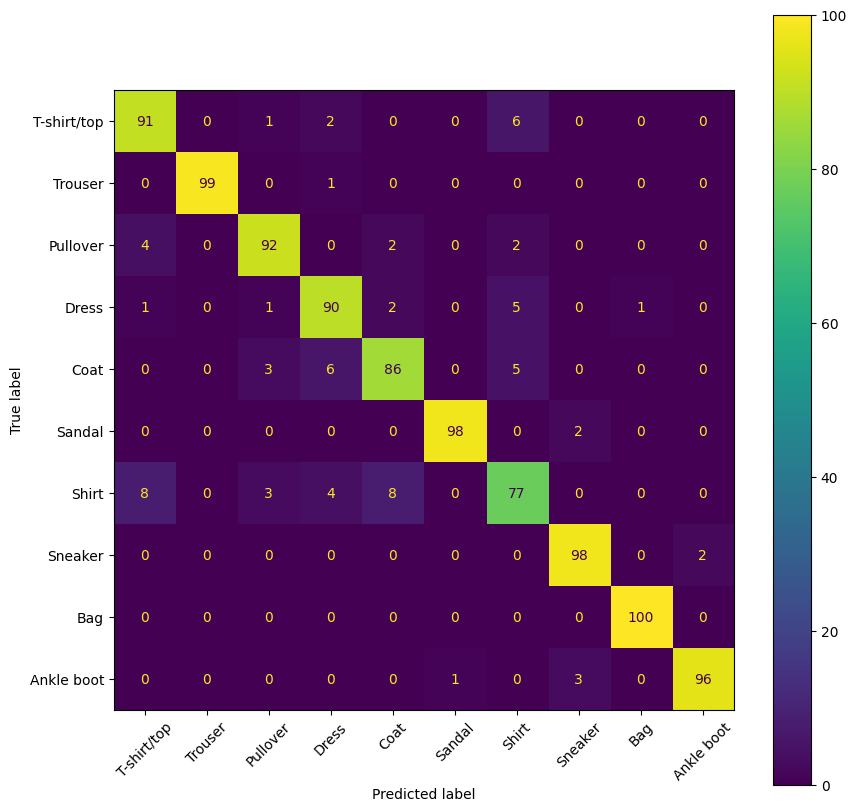

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()